# Processing — from `data/final/` to `data/processed/`

**What this notebook does.** Walks through the cleaning step (`src/processing/`) and shows the evidence for each change: the problem in the scraped tables, the rule that fixes it, and the result. It does not re-implement the pipeline: it runs `clean.run()` (or reads its output) and compares raw and cleaned tables.

**Data.** NYC 9/11 document archive (<https://911records.org>), scraped by the team into `data/final/*.parquet` (`git lfs pull`). `data/final/` is never modified; the cleaned tables go to `data/processed/` (gitignored).

**Where things are.** How to run, files, outputs and checks: [`src/processing/README.md`](../src/processing/README.md). Findings, with numbers and caveats: [`docs/01.processing_report.md`](../docs/01.processing_report.md).

**Contents.** 1 Run and row counts · 2 Off-topic documents · 3 Dates · 4 Page text, stamps and usable text · 5 Names · 6 Buildings · 7 Verification · 8 Summary

In [1]:
import os
from pathlib import Path
if Path.cwd().name == "notebooks":          # run from the repo root so `src` and `data/` resolve
    os.chdir(Path.cwd().parent)
import pandas as pd
from IPython.display import Image, display
import config
from src.processing import clean, dates, figures, settings, verify
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 80); pd.set_option("display.max_columns", 20)
RAW, P = config.FINAL, settings.PROCESSED
assert (RAW / "documents.parquet").stat().st_size > 10_000, "data/final holds Git LFS pointers: run `git lfs pull`"
print("working dir:", Path.cwd())

working dir: …/nyc-911-records-analysis


## 1. Run the cleaning and compare row counts

`clean.run()` reads `data/final/`, applies every step in order and writes `data/processed/` (about a minute). Set `RERUN = False` to reuse tables already written by `python -m src.processing.clean`.

In [2]:
RERUN = not (P / "removed_documents.parquet").exists()
if RERUN:
    clean.run()

TABLES = ["documents", "pages", "entities", "entity_mentions", "buildings", "building_mentions", "catalog_changes"]
rows = pd.DataFrame({
    "raw (data/final)": [pd.read_parquet(RAW / f"{t}.parquet", columns=[]).shape[0] for t in TABLES],
    "cleaned (data/processed)": [pd.read_parquet(P / f"{t}.parquet", columns=[]).shape[0] for t in TABLES],
}, index=TABLES)
rows["removed"] = rows.iloc[:, 0] - rows.iloc[:, 1]
rows

,raw (data/final),cleaned (data/processed),removed
documents,64619,64541,78
pages,230888,230315,573
entities,15915,15915,0
entity_mentions,650196,649168,1028
buildings,984,984,0
building_mentions,16151,16151,0
catalog_changes,794,794,0


In [3]:
# the tables used below
raw_docs = pd.read_parquet(RAW / "documents.parquet")
docs = pd.read_parquet(P / "documents.parquet")
removed = pd.read_parquet(P / "removed_documents.parquet")
pages = pd.read_parquet(P / "pages.parquet", columns=["doc_id", "page", "ocr_status", "litigation_stamp",
                                                     "litigation_source", "n_chars", "alpha_ratio", "word_ratio",
                                                     "has_usable_text", "date", "building_bins"])
entities = pd.read_parquet(P / "entities.parquet")
mentions = pd.read_parquet(P / "entity_mentions.parquet", columns=["entity_type", "entity_id", "doc_id", "page"])

**Reading.** Only the tables keyed by `doc_id` lose rows: 78 documents, their 573 pages and their entity mentions. `entities`, `buildings` and `catalog_changes` keep every row; they gain columns.

## 2. Off-topic documents

Two boxes hold City legal and insurance files unrelated to 9/11. Title searches ("flood", "claim") also catch real 9/11 documents, so the rule uses the box, with an exception for any document whose title or description mentions the WTC, Ground Zero or 9/11.

In [4]:
in_boxes = raw_docs[raw_docs["box"].isin(settings.OFF_TOPIC_BOXES)]
print(f"{len(in_boxes)} documents in {settings.OFF_TOPIC_BOXES}: {len(removed)} removed, "
      f"{len(in_boxes) - len(removed)} kept because they mention the WTC")
print("\nremoved, by folder:")
print(removed.groupby(["box", "folder"]).size().sort_values(ascending=False).head(10).to_string())

87 documents in ('DEP Box 41', 'GRM 010290082 - BOX 26'): 78 removed, 9 kept because they mention the WTC

removed, by folder:
box                     folder                                                
DEP Box 41              “MISC”                                                    9
                        “Lyndenwood Flood - Howerd Bch 4-30-14”                   9
                        “2007 Steam Pipe Explosion - 41st St. + Lexington Ave”    8
                        “DDC Active Construction Project List”                    8
                        “PUBLIC AFFAIRS INQUIRY”                                  7
GRM 010290082 - BOX 26  “MISC”                                                    5
DEP Box 41              “E41&LEX”                                                 4
                        “Archiving Material Claims Only”                          3
GRM 010290082 - BOX 26  “PUBLIC AFFAIRS INQUIRY”                                  3
                        “Requests 2012

In [5]:
# the documents kept by the exception
in_boxes[~in_boxes["doc_id"].isin(removed["doc_id"])][["doc_id", "box", "title"]]

,doc_id,box,title
20043,NYC-WTC_000159197,DEP Box 41,"World Trade Center subpoena receipt and response, Nov 2013"
20048,NYC-WTC_000159217,DEP Box 41,Fax memo from DEP Legal Affairs regarding WTC site
20050,NYC-WTC_000159223,DEP Box 41,"Possible hold notice, World Trade Center site"
20067,NYC-WTC_000159306,DEP Box 41,"2012 Request Record, DEP Box 41"
20070,NYC-WTC_000159347,DEP Box 41,"Notice of filing stipulation of settlement, September 2012"
20093,NYC-WTC_000159574,DEP Box 41,"2010 Request Record, DEP Box 41"
20096,NYC-WTC_000159579,DEP Box 41,"2011 Request Record, DEP Box 41"
20104,NYC-WTC_000159594,DEP Box 41,"DEP Request Record, WTC Site, Oct 2001"
20105,NYC-WTC_000159595,DEP Box 41,"DEP Data Sheet, WTC Site, Oct 2001"


**Reading.** The removed folders are about a 2007 steam-pipe explosion, a 2014 Howard Beach flood, Hurricane Irene and later insurance claims. The 9 kept documents (a WTC subpoena response, a hold notice for the WTC site, request records and data sheets for the site) are filed in the same boxes but are about the WTC. All 78 removals are listed in `removed_documents.parquet`.

## 3. Dates

The site dates each document by the **earliest date anywhere in its text**. Below: documents whose site date is one of the repeated dates `dates.py` detects, with the title that shows the real date.

In [6]:
cand = pd.Series([dates.raw_dates(r, s) for r, s in zip(docs["doc_date_raw"], docs["site_date"])], index=docs.index)
periods = docs["title"].map(dates.title_period)
repeated = sorted(dates.find_repeated_dates(cand, periods))
print(f"{periods.notna().sum():,} titles carry a date; repeated dates ignored:", [d.date().isoformat() for d in repeated])

cols = ["title", "site_date", "doc_date", "date_fix"]
examples = pd.concat([docs[docs["site_date"].dt.normalize() == pd.Timestamp(day)].head(2)
                      for day in ["1994-08-15", "1999-01-01", "2001-04-12"]])
examples[cols]

25,604 titles carry a date; repeated dates ignored: ['1994-08-15', '1997-12-03', '1999-01-01', '1999-07-31', '2000-09-06', '2001-02-04', '2001-04-12', '2001-07-16']


,title,site_date,doc_date,date_fix
9291,"Asbestos air sample analysis request, 100 Wall Street, Sep 2001",1994-08-15,2001-09-14,raw date matching title
9388,"Air monitoring report cover sheet, 345 South End Ave, 2001",1994-08-15,2001-09-26,raw date matching title
13822,"DEP memo on WTC building assessment guidance, February 2002",1999-01-01,2002-02-01,title date (no raw date)
13823,"DEP letter on WTC building safety, February 2002",1999-01-01,2002-02-01,title date (no raw date)
145,"GCMS method documentation header, Jan-Feb 2002",2001-04-12,2002-01-01,title date (no raw date)
161,"DEP GCMS sample label page, Jan-Feb 2002",2001-04-12,2002-01-01,title date (no raw date)


In [7]:
# documents the site dates on 9/11 itself: mostly later documents that mention the attack
on_911 = docs["site_date"].dt.normalize() == pd.Timestamp("2001-09-11")
print(f"site date 9/11/2001: {on_911.sum()} documents; corrected date 9/11/2001: "
      f"{(docs['doc_date'].dt.normalize() == pd.Timestamp('2001-09-11')).sum()}")
docs[on_911 & (docs["doc_date"].dt.normalize() != pd.Timestamp("2001-09-11"))][cols].head(4)

site date 9/11/2001: 591 documents; corrected date 9/11/2001: 162


,title,site_date,doc_date,date_fix
6134,"Selenium analytical results, Oct 3, 2001",2001-09-11,2001-10-04,raw date matching title
8689,"License agreement for exterior cleanup, NYC DEP, Oct 2002",2001-09-11,2002-10-01,title date (raw date implausible)
8922,"License agreement for exterior cleanup near WTC site, April 2002",2001-09-11,2002-04-01,title date (raw date implausible)
9029,"License agreement terms on funding and termination, July 2002",2001-09-11,2002-07-01,title date (raw date implausible)


**What happened to every date.** Two views: which rule set the date (`date_fix`), and how the result compares with the site's date.

In [8]:
outcome = figures.date_outcomes(docs)
pd.crosstab(outcome, docs["date_fix"], margins=True)

date_fix,no date,raw date (conflicts with title),raw date (no title date),raw date matching title,title date (no raw date),title date (raw date implausible),All
row_0,,,,,,,
missing date filled in,0,0,0,0,6638,0,6638
no date before or after,6746,0,0,0,0,0,6746
site date confirmed by title,0,0,0,15037,0,0,15037
"site date kept, title disagrees",0,1270,0,0,0,0,1270
"site date kept, title has no date",0,0,32160,0,0,0,32160
site date replaced,0,13,11,1997,147,502,2670
"wrong date removed, none left",20,0,0,0,0,0,20
All,6766,1283,32171,17034,6785,502,64541


In [9]:
before = docs["site_date"].dt.year.value_counts()
after = docs["doc_date"].dt.year.value_counts()
years = pd.DataFrame({"site_date": before, "doc_date": after}).fillna(0).astype(int)
print(f"undated documents: {docs['site_date'].isna().sum():,} before, {docs['doc_date'].isna().sum():,} after")
print(f"in the study window ({settings.STUDY_START} to {settings.STUDY_END}): {docs['in_study_window'].sum():,} "
      f"of {len(docs):,}")
print(docs["date_precision"].value_counts(dropna=False).to_string())
years.loc[1993:2003]

undated documents: 13,384 before, 6,766 after
in the study window (2001-09-11 to 2009-12-31): 54,293 of 64,541
date_precision
day      51049
NaN       6766
month     5687
year      1039


,site_date,doc_date
1993.0,38,33
1994.0,198,20
1995.0,22,16
1996.0,23,22
1997.0,186,228
1998.0,1122,1483
1999.0,536,714
2000.0,123,149
2001.0,9216,11199
2002.0,38205,42114


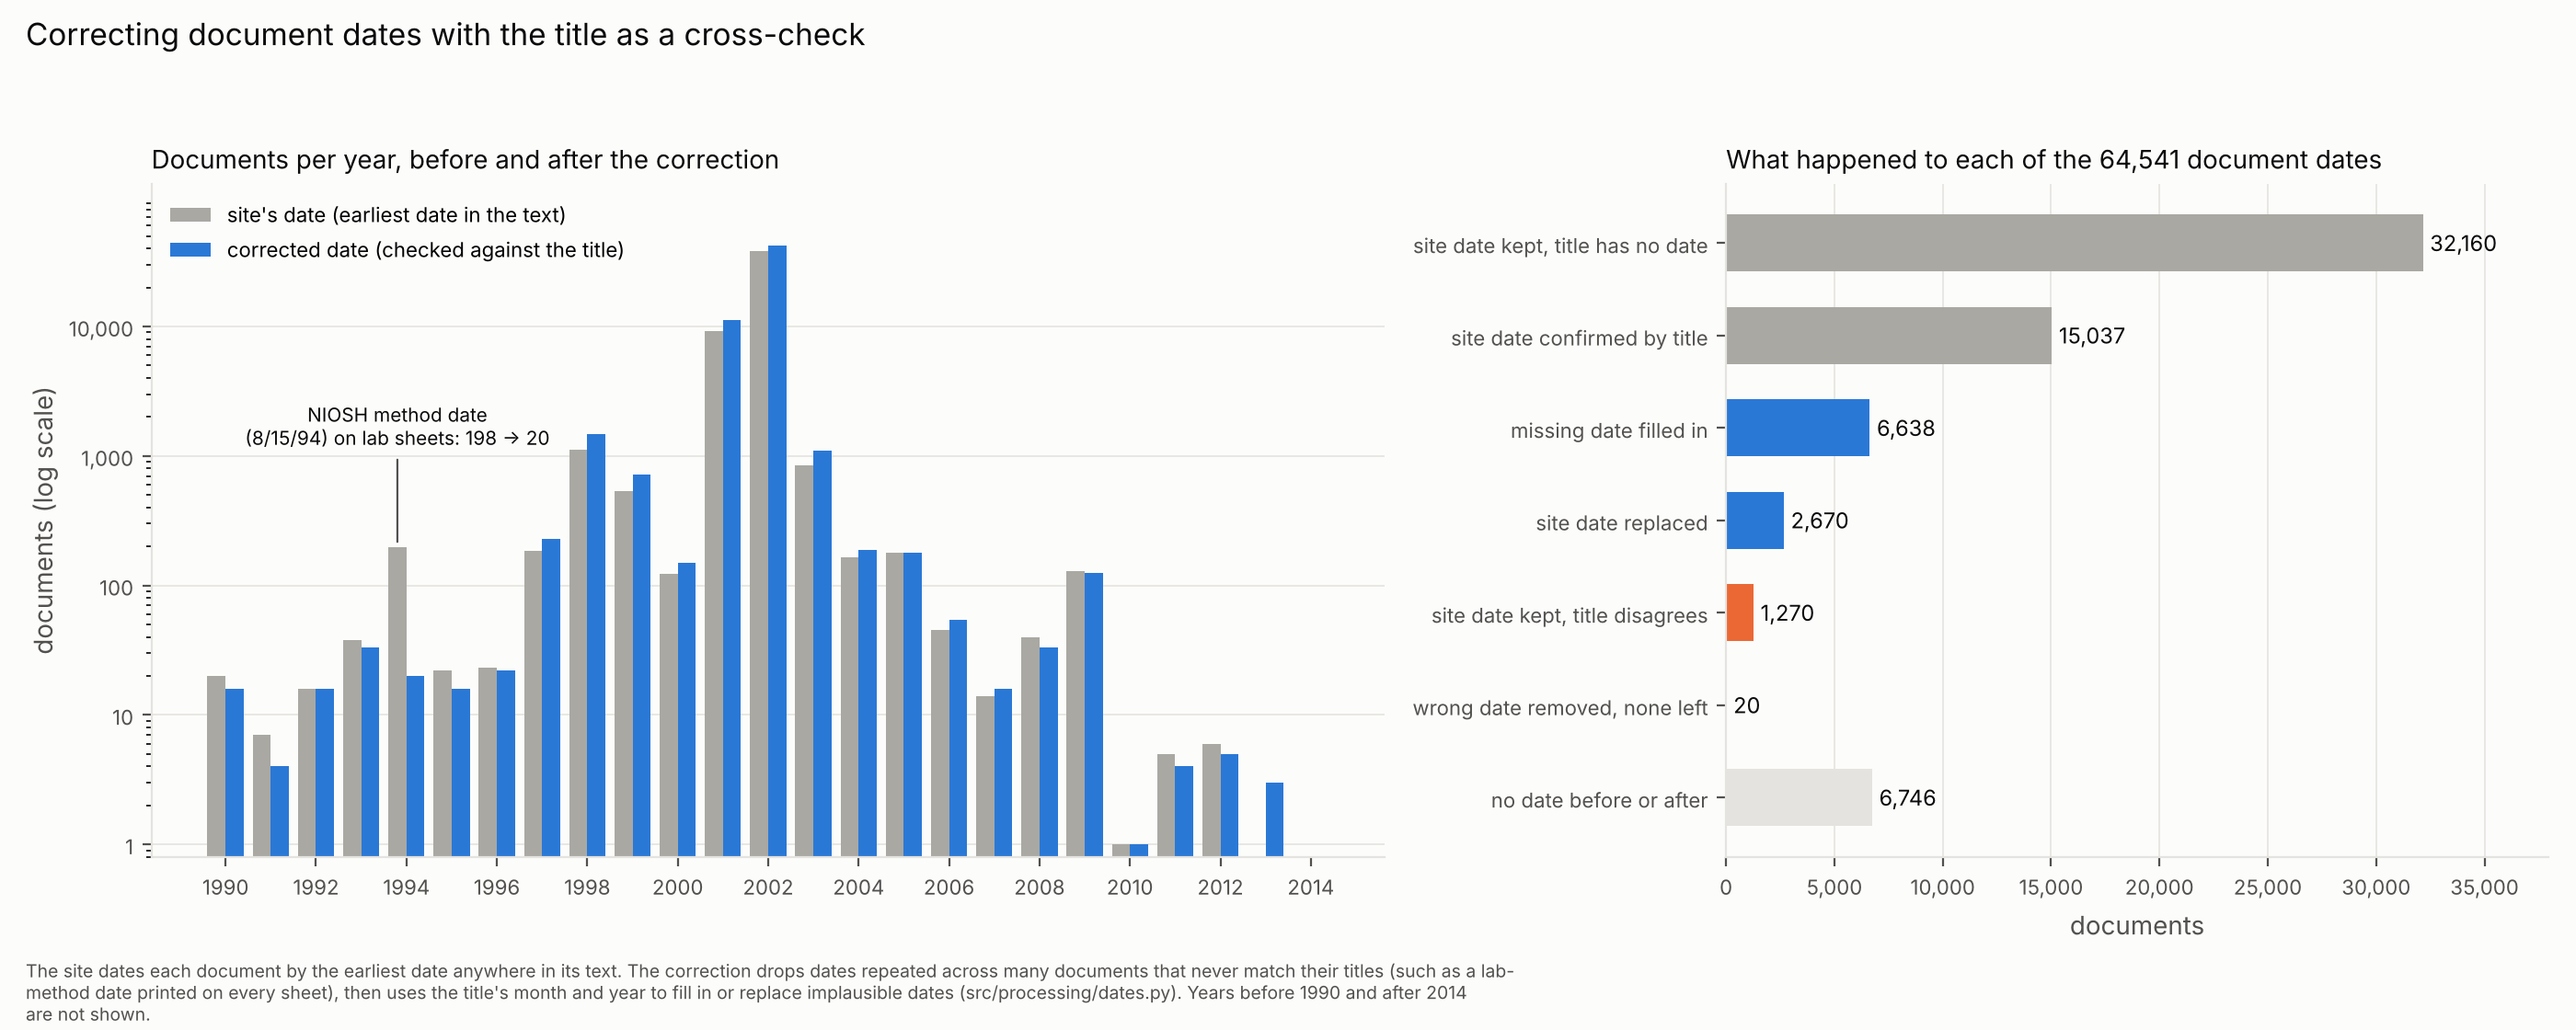

In [10]:
display(Image(str(figures.dates_figure(docs))))

**Reading.**
* 47,197 site dates are kept: 15,037 confirmed by the title and 32,160 that cannot be checked because the title has no date.
* 6,638 missing dates are filled in from the title and 2,670 wrong ones replaced; 1,270 dates disagree with the title but are both plausible, so they are kept and flagged (`raw date (conflicts with title)`).
* The repeated dates are the false history: 1994 falls from 198 documents to 20, because 181 documents carried the NIOSH 7400 method date of 15 Aug 1994.
* Undated documents fall from 13,384 to 6,766.
* Dates taken from a title are stored on the 1st of the month (5,687) or 1 January (1,039). Monthly counts must drop `date_precision == "year"`; daily or weekly counts must keep only `"day"`.

## 4. Page text, litigation stamps and usable text

One raw page and its cleaned version: the portal header, the Bates number and the litigation stamp are removed from the text, and the stamp is kept in its own column.

In [11]:
doc_id, page = "NYC-WTC_000178163", 6
raw_page = pd.read_parquet(RAW / "pages.parquet", filters=[("doc_id", "==", doc_id)])
raw_page = raw_page[raw_page["page"] == page]
clean_page = pd.read_parquet(P / "pages.parquet", filters=[("doc_id", "==", doc_id)])
clean_page = clean_page[clean_page["page"] == page]
print("RAW  :", raw_page["text"].iloc[0][:400].replace("\n", " | "))
print("...  :", raw_page["text"].iloc[0][-120:].replace("\n", " | "))
print()
print("CLEAN:", clean_page["text"].iloc[0][:400].replace("\n", " | "))
print("...  :", clean_page["text"].iloc[0][-120:].replace("\n", " | "))
clean_page[["litigation_stamp", "litigation_source", "n_chars", "alpha_ratio", "word_ratio", "has_usable_text"]]

RAW  : NYC 9/11 Public Portal Document |  | ATTACHMENT 1 | WTC Indoor Air Sampling Matrix Background Study | Samples Numbers Shown are Per Unit | Asbestos/ | MMVF |  | Lead |  | Dioxins |  | PAHs |  | Silica |  | 1 | 1 | 1 |  | 0 | 1 | 1 |  | 0 | 1 | 1 |  | 0 | 1 | 1 |  | 0 | 1 | 1 |  | 1 |  | 1 |  | 1 |  | 1 |  | 1 |  | 5 |  | Total Wipe | Samples/parameter |  | 4 |  | 3 |  | 3 |  | 3 |  | 3 |  | 16 |  | Micro-vacuum | Samples |  | Asbestos/ | MMVF |  | Lead |  | Dioxins |  | PAHs |  | Silica |  | Carpets or Drapery |  | 3 |  | 3 |  | 0 |  | 0 |  | 0 |  | Fabric Furniture | (couc
...  : ts | 32 sampfes/unit x 42 units = 1344 samples + 134 QC samples = 1478 samples |  | CITY_21MC100_011836898 | NYC-WTC_000178168 |  | 

CLEAN: ATTACHMENT 1 | WTC Indoor Air Sampling Matrix Background Study | Samples Numbers Shown are Per Unit | Asbestos/ | MMVF | Lead | Dioxins | PAHs | Silica | 1 | 1 | 1 | 0 | 1 | 1 | 0 | 1 | 1 | 0 | 1 | 1 | 0 | 1 | 1 | 1 | 1 | 1 | 1 | 1 | 5 | Total Wipe | Samples/param

,litigation_stamp,litigation_source,n_chars,alpha_ratio,word_ratio,has_usable_text
5,CITY_21MC100_011836898,21MC100,1091,0.874,0.633,True


In [12]:
print("pages by litigation source:")
print(pages["litigation_source"].fillna("(no stamp)").value_counts().to_string())
stamped_docs = pages.loc[pages["litigation_source"].notna(), "doc_id"].nunique()
print(f"\ndocuments with at least one stamp: {stamped_docs:,} of {pages['doc_id'].nunique():,} with pages "
      f"({stamped_docs / pages['doc_id'].nunique():.0%})")

pages by litigation source:
litigation_source
(no stamp)                   183264
21MC100                       45970
DEP_WORBY_CANNATA_SUBP         1041
DEP_20BROAD_MCGIVNEY_SUBP        19
DEP_63WALL_MCGIVNEY_SUBP         18
DEP_60BROAD_MCGIVNEY_SUBP         3

documents with at least one stamp: 36,475 of 64,307 with pages (57%)


**Usable text.** The site's `ocr_status` label against `has_usable_text` (≥ 100 characters, ≥ 50% letters, ≥ 40% of tokens real words of 3+ letters).

In [13]:
pd.crosstab(pages["ocr_status"], pages["has_usable_text"], margins=True)

has_usable_text,False,True,All
ocr_status,,,
empty,2097,0,2097
junk,3980,0,3980
ocr,6383,3819,10202
ok,67305,146731,214036
All,79765,150550,230315


'ok' pages that fail: 67,305
  fewer than 100 characters : 3,425
  under 50% letters         : 41,203
  under 40% words           : 64,340


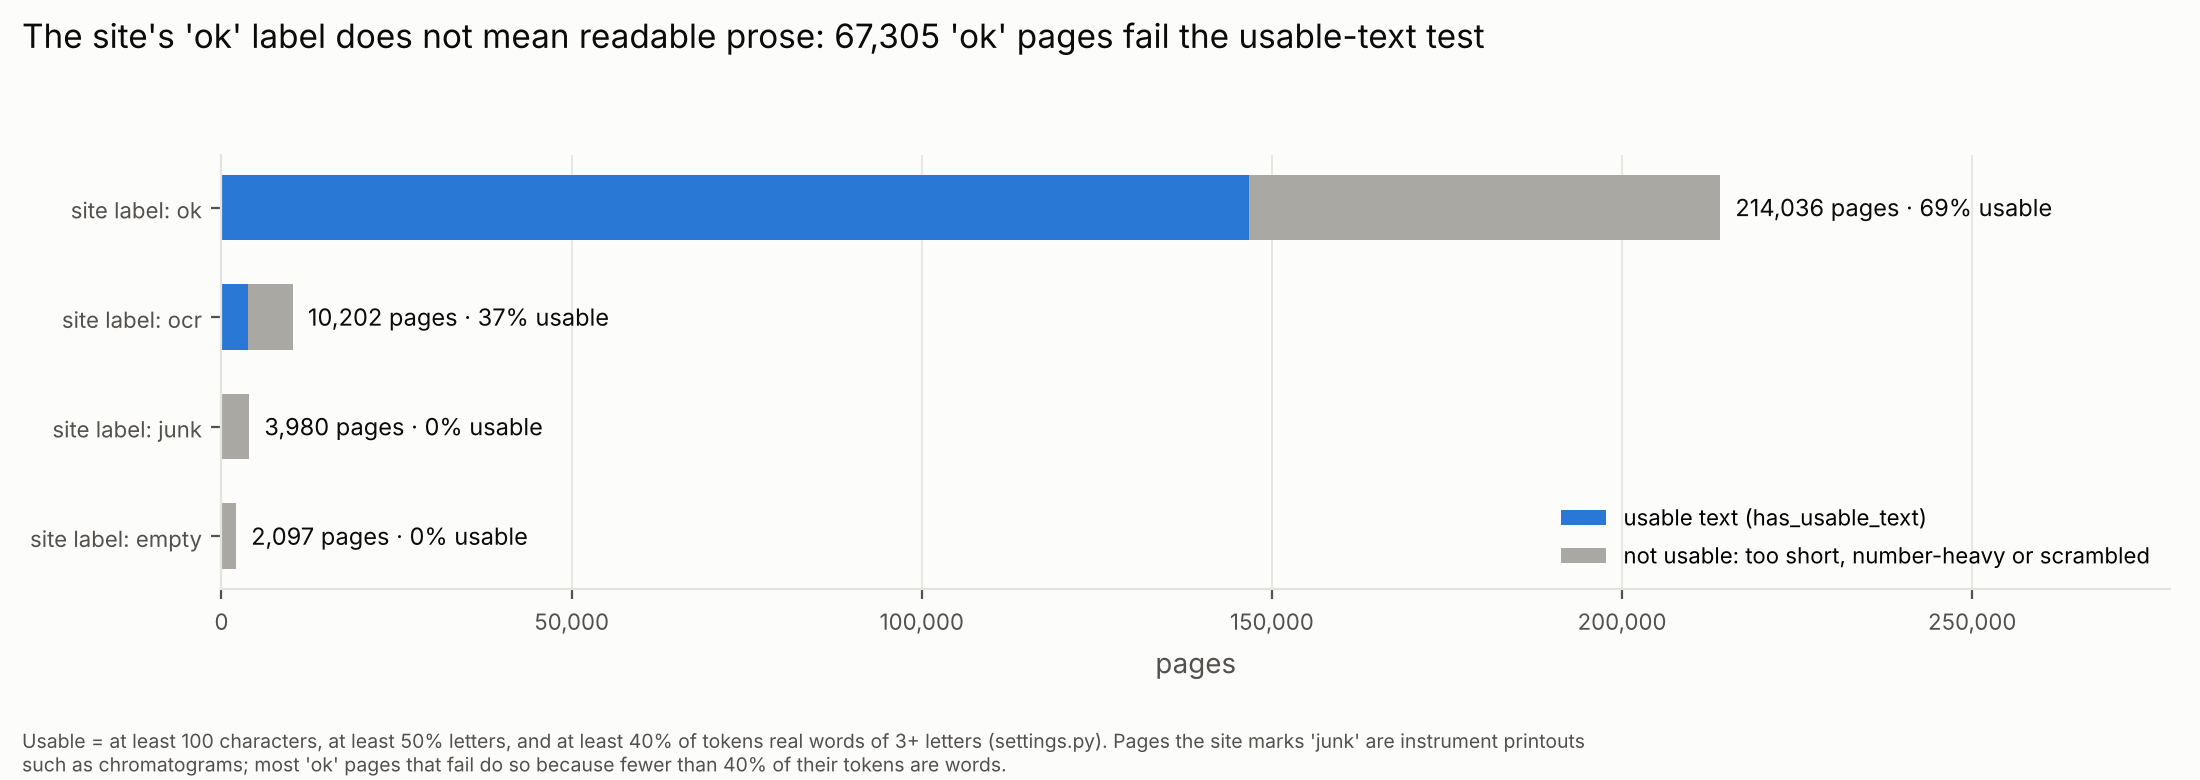

In [14]:
ok_fail = pages[(pages["ocr_status"] == "ok") & ~pages["has_usable_text"]]
print(f"'ok' pages that fail: {len(ok_fail):,}")
print("  fewer than 100 characters :", f"{(ok_fail['n_chars'] < settings.MIN_USABLE_CHARS).sum():,}")
print("  under 50% letters         :", f"{(ok_fail['alpha_ratio'] < settings.MIN_ALPHA_RATIO).sum():,}")
print("  under 40% words           :", f"{(ok_fail['word_ratio'] < settings.MIN_WORD_RATIO).sum():,}")
display(Image(str(figures.usable_text_figure(pages))))

**Reading.**
* 36,475 of the 64,307 documents with pages (57%) carry a litigation stamp, almost all from the WTC disaster-site litigation (21 MC 100). The stamps are removed from the text, where they would count as words, and kept as data.
* 150,550 of 230,315 pages (65%) are usable prose. The site's label does not say which: 67,305 "ok" pages fail, mostly on the word test (tables of numbers and codes), and the 3,980 "junk" pages are instrument printouts, none usable.
* Text and sentiment analysis should select pages with `has_usable_text`, not `ocr_status`.

## 5. Names: one organization, one `entity_id`

In [15]:
ag = entities[entities["entity_type"] == "agency"]
print(f"agency names: {len(ag)} -> agencies: {ag['entity_id'].nunique()}")
print(ag.drop_duplicates("entity_id")["agency_level"].value_counts().to_string())
(ag.groupby(["entity_id", "agency_level"])["name"].agg(lambda s: " | ".join(s)).reset_index()
   .assign(n_names=lambda d: d["name"].str.count(r"\|") + 1)
   .sort_values("n_names", ascending=False).head(8))

agency names: 48 -> agencies: 30
agency_level
city         14
federal       7
state         4
private       2
nonprofit     2
regional      1


,entity_id,agency_level,name,n_names
2,lmdc,state,LMDC | Lower Manhattan Development Corporation | The Lower Manhattan Develop...,4
8,nyc-dohmh,city,Department of Health | DOH | DOHMH,3
24,us-epa,federal,Environmental Protection Agency | EPA | U.S. EPA,3
14,nyc-mayor,city,City Hall | Mayor's Office | Office of the Mayor,3
5,nyc-dep,city,DEP | Department of Environmental Protection,2
11,nyc-fdny,city,FDNY | Fire Department,2
13,nyc-law,city,Corporation Counsel | Law Department,2
10,nyc-dsny,city,Department of Sanitation | DSNY,2


In [16]:
for t in ("contractor", "lab"):
    x = entities[entities["entity_type"] == t]
    print(f"{t}: {len(x):,} names -> {x['entity_id'].nunique():,}")
merged = (entities[entities["entity_type"] == "contractor"].groupby("entity_id")
          .agg(n_names=("name", "size"), names=("name", lambda s: " | ".join(s[:4]))))
merged.sort_values("n_names", ascending=False).head(8)   # the largest groups include extraction fragments ("Mgmt", "St")

contractor: 6,254 names -> 6,043
lab: 1,136 names -> 1,124


,n_names,names
entity_id,,
mgmt,4,Mgmt Co. | Mgmt Corp. | Mgmt Inc. | Mgmt LLC
st,3,St Corp. | St Inc. | St LLC
safeway-environmental,3,Safeway Environmental Corp. | Safeway Environmental Inc. | The Safeway Envir...
it,3,It Co. | It Corp. | The It Corp.
heavy-construction,3,Heavy Construction | Heavy Construction Co Inc. | Heavy Construction Co.
ambassador-construction,3,Ambassador Construction | Ambassador Construction Co. | Ambassador Construct...
power,3,Power Co. | Power Corp. | Power Inc.
chambers,3,Chambers Co. | Chambers Company LLC | Chambers LLC


In [17]:
dup = mentions.duplicated(["entity_type", "entity_id", "doc_id", "page"]).sum()
print(f"mention rows that repeat an organization on the same page after merging: {dup:,} -> deduplicate per page")

mention rows that repeat an organization on the same page after merging: 9,475 -> deduplicate per page


**Reading.** 48 agency names — the site's 46, plus 2 Lower Manhattan Development Corporation names it filed as contractors — become 30 agencies (14 city, 7 federal, 4 state, 2 private, 2 nonprofit, 1 regional). 6,254 contractor names become 6,043 companies and 1,136 lab names 1,124 labs. Some merged "companies" are extraction fragments ("Mgmt Inc.", "St LLC"); merging does not remove them. Counts by `entity_id` must be deduplicated per page.

## 6. Buildings

In [18]:
raw_b = pd.read_parquet(RAW / "buildings.parquet")
b = pd.read_parquet(P / "buildings.parquet")
before_after = raw_b[["bin", "units", "building_area", "building_class"]].merge(
    b[["bin", "residential_units", "total_units", "building_area_sqft", "building_class_code", "in_lower_manhattan"]], on="bin")
print(f"buildings outside the Lower Manhattan box {settings.LOWER_MANHATTAN_BBOX}: {(~b['in_lower_manhattan']).sum()} of {len(b)}")
print(f"pages naming at least one building: {(pages['building_bins'].map(len) > 0).sum():,}")
before_after.head()

buildings outside the Lower Manhattan box (-74.03, 40.695, -73.97, 40.73): 14 of 984
pages naming at least one building: 27,606


,bin,units,building_area,building_class,residential_units,total_units,building_area_sqft,building_class_code,in_lower_manhattan
0,1000003,— residential / 2 total,"157,426 sq ft",hotel (H5),<NA>,2,157426.0,H5,True
1,1000004,— residential / 1 total,"123,800 sq ft",office (O2),<NA>,1,123800.0,O2,True
2,1000005,— residential / 63 total,"1,888,126 sq ft",condominium (RC),<NA>,63,1888126.0,RC,True
3,1000006,— residential / 26 total,"1,051,990 sq ft",condominium (RB),<NA>,26,1051990.0,RB,True
4,1000007,1320 residential / 1323 total,"1,044,351 sq ft",elevator apartments (D5),1320,1323,1044351.0,D5,True


**Reading.** Display strings become numbers ("9 residential / 11 total" → 9 and 11; "157,426 sq ft" → 157426.0). 14 of 984 buildings fall outside the study area; `in_lower_manhattan` lets the spatial analysis keep or drop them with one filter.

## 7. Verification

The same checks as `python -m src.processing.verify`: the rules on hand-made inputs with known answers, then the real output tables (bookkeeping, keys, joins, date ranges, text, entities, buildings). Any failure raises an error.

In [19]:
verify.check_date_rules()
verify.check_text_and_names()
verify.check_outputs()

1. date rules: title parsing, rules 2-4, repeated dates and valid range behave as documented
2-3. stamps, text cleaning, usable text, name merging, file size and the off-topic rule behave as documented


4. 64,619 raw documents = 64,541 kept + 78 removed; no removed document in any doc-keyed table


5. keys unique; every page has a document; every entity mention has a page
6. dates: 57,775 dated documents all in range; precision, date_fix, study window and page dates consistent


7. text: no portal header or Bates stamp left; has_usable_text follows settings.py (150,550 usable pages)
8. entities: every mention has an entity_id; 30 agencies, all with a level
9. buildings: in_lower_manhattan matches the bounding box (14 of 984 outside)


## 8. Summary

| Step | Problem in the scraped archive | Rule | Result |
| --- | --- | --- | --- |
| Off-topic | City legal and insurance files boxed with the 9/11 records | drop two boxes unless the document mentions the WTC | 78 documents, 573 pages removed and listed |
| Dates | site date = earliest date in the text (method dates, fax clocks, 9/11 mentions, print dates) | cross-check against the title; drop repeated dates | 6,638 filled in, 2,670 replaced, 1,270 flagged; undated 13,384 → 6,766; 1994: 198 → 20 |
| Page text | portal header, Bates and litigation stamps on every page | remove from text; keep stamps as columns | 57% of documents carry a litigation stamp |
| Usable text | site label (`ocr_status`) does not mark prose | length, letters, words thresholds | 150,550 of 230,315 pages (65%) usable |
| Names | one organization under several names | hand map for agencies; suffix normalisation for companies | 46 → 30 agencies; 6,254 → 6,043 contractors |
| Buildings | numbers stored as display text | parse; flag study area | 14 of 984 outside Lower Manhattan |

**For the analyses:** use `doc_date` and `date_precision`, `entity_id` deduplicated per page, `has_usable_text`, `in_study_window` and `in_lower_manhattan`. What is not fixed (forms in usable text, unchecked date conflicts, OCR spelling) is listed in the report, section 6.